## PCA, SVD, and Dimensionality Reduction

### Learning Goals
* Understand Principal Component Analysis (PCA) as an orthogonal basis transformation maximizing sample variance.
* Factorize feature matrices using Singular Value Decomposition (SVD): $X = U \Sigma V^T$.
* Understand why feature standardization is mandatory before dimensionality reduction and recognize the interpretability limits of principal components.

---

### 1. The Central Idea of PCA

Principal Component Analysis identifies orthogonal axes (linear combinations of original features) that capture maximum sample variation.

For a column-centered data matrix $X$, the sample covariance matrix is proportional to:
$$
X^T X
$$
The eigenvectors of $X^T X$ define the principal direction vectors, and the eigenvalues quantify the variance preserved along each corresponding direction.

> **Key Caution:** High variance does not inherently imply high predictive utility for a specific target variable; PCA is an unsupervised technique.

PCA Variance Breakdown:
  Component 1: 62.42% variance explained
  Component 2: 32.55% variance explained
  Component 3: 5.03% variance explained
Cumulative Variance: [0.62416033 0.94970247 1.        ]


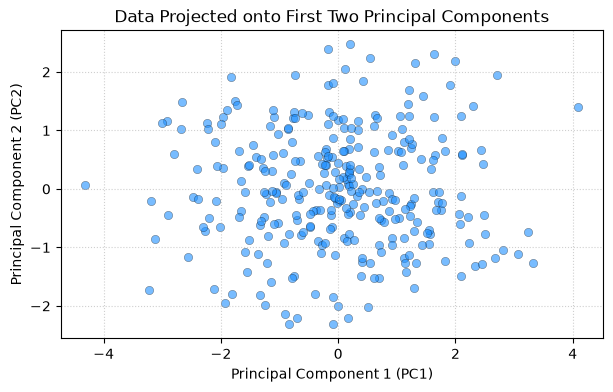

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(7)
latent = rng.normal(size=300)

# Generate synthetic correlated 3D features
X = np.column_stack([
    3 * latent + rng.normal(0, 0.5, 300),
    1.5 * latent + rng.normal(0, 0.8, 300),
    rng.normal(0, 2, 300),
])

X_scaled = StandardScaler().fit_transform(X)
pca = PCA()
transformed = pca.fit_transform(X_scaled)

print("PCA Variance Breakdown:")
for i, ratio in enumerate(pca.explained_variance_ratio_):
    print(f"  Component {i+1}: {ratio*100:.2f}% variance explained")
print(f"Cumulative Variance: {np.cumsum(pca.explained_variance_ratio_)}")

plt.figure(figsize=(7, 4))
plt.scatter(transformed[:, 0], transformed[:, 1], color='dodgerblue', alpha=0.6, edgecolor='k', linewidth=0.3)
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("Data Projected onto First Two Principal Components")
plt.grid(linestyle=':', alpha=0.6)
plt.show()

### 2. Singular Value Decomposition (SVD)

Singular Value Decomposition factorizes any real $m \times n$ matrix $X$ into three matrices:
$$
X = U \Sigma V^T
$$
where:
* $U$: Left singular vectors (orthonormal basis for row space).
* $\Sigma$: Diagonal matrix containing singular values (proportional to component standard deviations).
* $V^T$: Right singular vectors (principal component direction loadings).

SVD serves as the foundational computational engine for PCA, latent semantic analysis, recommendation engines, and low-rank matrix compression.

---

### Exercises

Try each problem before running the verification code below:

1. Compare the explained variance ratio of PC1 relative to the remaining components in the output above.
2. Why is feature scaling (`StandardScaler`) essential prior to performing PCA?
3. Explain one major limitation of using principal components when presenting results to non-technical stakeholders.

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print(f"\n1. Explained Variance Distribution:")
print(f"   - PC1 captures {pca.explained_variance_ratio_[0]*100:.1f}% of total variance, dominating remaining dimensions.")

print("\n2. Why Standardization is Essential:")
print("   - PCA maximizes variance; unscaled features measured in larger units (e.g., income in dollars")
print("     vs. age in years) will artificially dominate principal component directions regardless of structure.")

print("\n3. Interpretability Limitation:")
print("   - Principal components are linear combinations of all original inputs, making it difficult")
print("     to map individual PC dimensions back to actionable, intuitive real-world domain domain concepts.")

=== Exercise Solutions & Checks ===

1. Explained Variance Distribution:
   - PC1 captures 62.4% of total variance, dominating remaining dimensions.

2. Why Standardization is Essential:
   - PCA maximizes variance; unscaled features measured in larger units (e.g., income in dollars
     vs. age in years) will artificially dominate principal component directions regardless of structure.

3. Interpretability Limitation:
   - Principal components are linear combinations of all original inputs, making it difficult
     to map individual PC dimensions back to actionable, intuitive real-world domain domain concepts.
